# E2: point-lookup cost vs n (track_id, file order)

Question: how does the cost of `search` grow with n, for hits and for misses, and does it match the big-O we expect?
Data: `E2_point_lookups` rows from `results/timings.csv`, one machine, one code version.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv(Path("..") / "results" / "timings.csv")
e2 = df[df["experiment"] == "E2_point_lookups"]

# Control the comparison: one machine, one code version.
machine = "zaid-mbp"
BEFORE, AFTER = "45879fa", "fa5c1ad"   # original code vs the code with all fixes
all_e2 = e2[e2["machine_id"] == machine]
version = BEFORE   # everything down to the Observations section is on the original code
e2 = all_e2[all_e2["code_version"] == version].copy()

# Each row is a batch of n_ops lookups, so divide to get cost per lookup.
e2["us_per_op"] = e2["total_ns"] / e2["n_ops"] / 1_000
for c in ["comparisons", "nodes_visited", "resizes"]:
    e2[c + "_per_op"] = e2[c] / e2["n_ops"]

print(machine, version, len(e2), "rows")
e2.groupby(["index_type", "operation"]).size().unstack()

zaid-mbp 45879fa 490 rows


operation,point_hit,point_miss
index_type,,
avl_tree,35,35
bplus_tree,35,35
hash_table,35,35
ref_bisect,35,35
ref_dict,35,35
sorted_list,35,35
unsorted_list,35,35


## Median and IQR across the 5 replicates

In [2]:
def summarize(g):
    return pd.Series({
        "q25": g.quantile(0.25), "median": g.median(), "q75": g.quantile(0.75),
    })

summary = (
    e2.groupby(["operation", "index_type", "n_keys"])["us_per_op"]
    .apply(lambda g: summarize(g)).unstack()
)
summary.round(2).head(14)

q25  median   q75
operation index_type n_keys                    
point_hit avl_tree   1000    0.63    0.65  0.68
                     2000    0.70    0.72  0.72
                     5000    0.76    0.80  0.81
                     10000   0.87    0.89  0.91
                     20000   1.05    1.09  1.53
                     50000   1.58    1.74  1.88
                     114000  2.54    2.93  2.95
          bplus_tree 1000    1.27    1.29  1.30
                     2000    1.34    1.37  1.38
                     5000    1.42    1.43  1.45
                     10000   1.59    1.61  1.64
                     20000   1.81    1.92  1.93
                     50000   2.32    2.50  2.62
                     114000  3.90    4.18  5.19

## Cost vs n, log-log

On log-log axes, cost proportional to n^k is a straight line of slope k. Line = median over replicates, band = IQR.

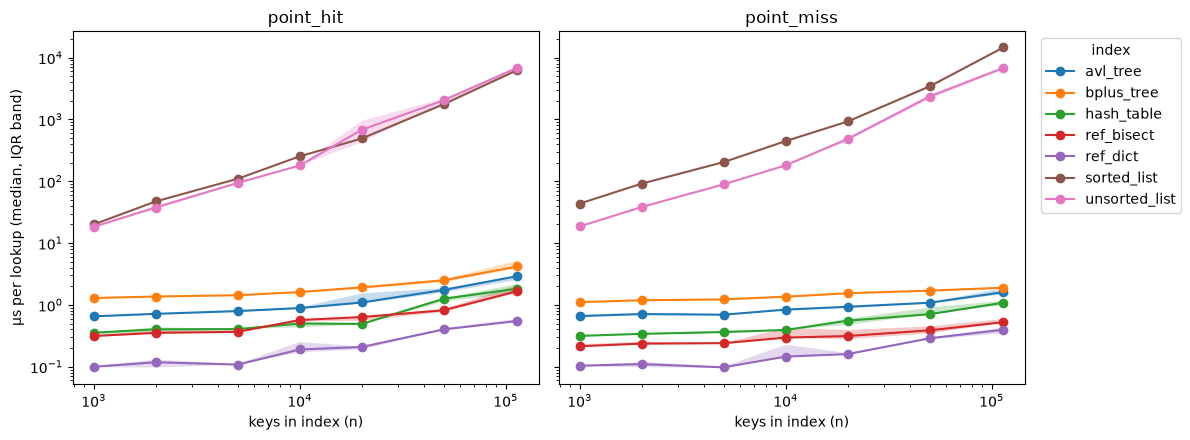

In [3]:
ops = ["point_hit", "point_miss"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, op in zip(axes, ops):
    for index_type, g in e2[e2["operation"] == op].groupby("index_type"):
        s = summary.loc[(op, index_type)]
        ax.plot(s.index, s["median"], marker="o", label=index_type)
        ax.fill_between(s.index, s["q25"], s["q75"], alpha=0.25)
    ax.set(xscale="log", yscale="log", title=op, xlabel="keys in index (n)")
axes[0].set_ylabel("µs per lookup (median, IQR band)")
axes[1].legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Fitted slopes vs expected big-O

Fit log10(cost) = a + k·log10(n) to the per-n medians. The interval comes from a bootstrap over replicates:
for each n, resample the 5 replicates with replacement, take the median, refit, repeat.

In [4]:
rng = np.random.default_rng(4300)
expected = {"unsorted_list": 1.0, "sorted_list": 0.0, "hash_table": 0.0,
            "avl_tree": 0.0, "bplus_tree": 0.0, "ref_dict": 0.0, "ref_bisect": 0.0}  # log n shows up as a small positive slope

def slope(ns, costs):
    return np.polyfit(np.log10(ns), np.log10(costs), 1)[0]

rows = []
for (op, index_type), g in e2.groupby(["operation", "index_type"]):
    by_n = {n: grp["us_per_op"].to_numpy() for n, grp in g.groupby("n_keys")}
    ns = sorted(by_n)
    k = slope(ns, [np.median(by_n[n]) for n in ns])
    boot = [
        slope(ns, [np.median(rng.choice(by_n[n], size=len(by_n[n]))) for n in ns])
        for _ in range(1000)
    ]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"operation": op, "index_type": index_type, "slope": k, "ci_lo": lo, "ci_hi": hi})

slopes = pd.DataFrame(rows).round(2)
slopes.sort_values(["operation", "slope"])

,operation,index_type,slope,ci_lo,ci_hi
1,point_hit,bplus_tree,0.23,0.19,0.32
0,point_hit,avl_tree,0.30,0.27,0.33
3,point_hit,ref_bisect,0.33,0.30,0.38
2,point_hit,hash_table,0.34,0.29,0.39
4,point_hit,ref_dict,0.37,0.35,0.42
5,point_hit,sorted_list,1.18,1.15,1.22
6,point_hit,unsorted_list,1.26,1.22,1.30
8,point_miss,bplus_tree,0.12,0.10,0.12
7,point_miss,avl_tree,0.17,0.13,0.28
10,point_miss,ref_bisect,0.18,0.14,0.23


Expected: unsorted list is O(n), slope about 1. Hash table is O(1) on average, slope about 0.
Tree and binary-search indexes are O(log n); over this range of n that appears as a small positive slope (0.1 to 0.2).

The unsorted list has a slope of 1.26 for hits (CI 1.22 to 1.30) and 1.26 for misses (1.22 to 1.31). That is linear growth, though a bit steeper than the expected 1. The hash table has a slope of 0.34 for hits (0.29 to 0.39) and 0.25 for misses (0.23 to 0.30). It is not perfectly flat, but the gap between the two is huge. At n = 114,000 the unsorted list costs about 7,000 µs per lookup and the hash table about 2 µs.

Both slopes sit about 0.3 above the expected values. The built-in ref_dict shows the same drift (0.37 hit, 0.29 miss), and the hash table's comparison counts stay flat (slope 0.01 for hits, 0.09 for misses). So the extra slope probably comes from the machine rather than the algorithm, most likely from cache misses as memory use grows. I haven't tested that directly.

In [5]:
# Same fit on the deterministic counters (no replicate noise). Counters are per-op averages.
rows = []
for (op, index_type), g in e2[e2["comparisons"].notna()].groupby(["operation", "index_type"]):
    med = g.groupby("n_keys")[["comparisons_per_op", "nodes_visited_per_op"]].median()
    rows.append({"operation": op, "index_type": index_type,
                 "comparisons_slope": slope(med.index, med["comparisons_per_op"].clip(lower=1e-9)),
                 "nodes_slope": slope(med.index, med["nodes_visited_per_op"].clip(lower=1e-9))})
pd.DataFrame(rows).round(2).sort_values(["operation", "index_type"])

,operation,index_type,comparisons_slope,nodes_slope
0,point_hit,avl_tree,0.11,0.11
1,point_hit,bplus_tree,0.11,0.08
2,point_hit,hash_table,0.01,0.00
3,point_hit,sorted_list,0.97,0.00
4,point_hit,unsorted_list,1.00,0.00
5,point_miss,avl_tree,0.11,0.11
6,point_miss,bplus_tree,0.11,0.08
7,point_miss,hash_table,0.09,0.00
8,point_miss,sorted_list,0.96,0.00
9,point_miss,unsorted_list,1.00,0.00


## Counters vs n

Comparisons and nodes visited per lookup, at each n, with log2(n) and n/2 for reference lines.
`resizes` is also in the data; we check it below.

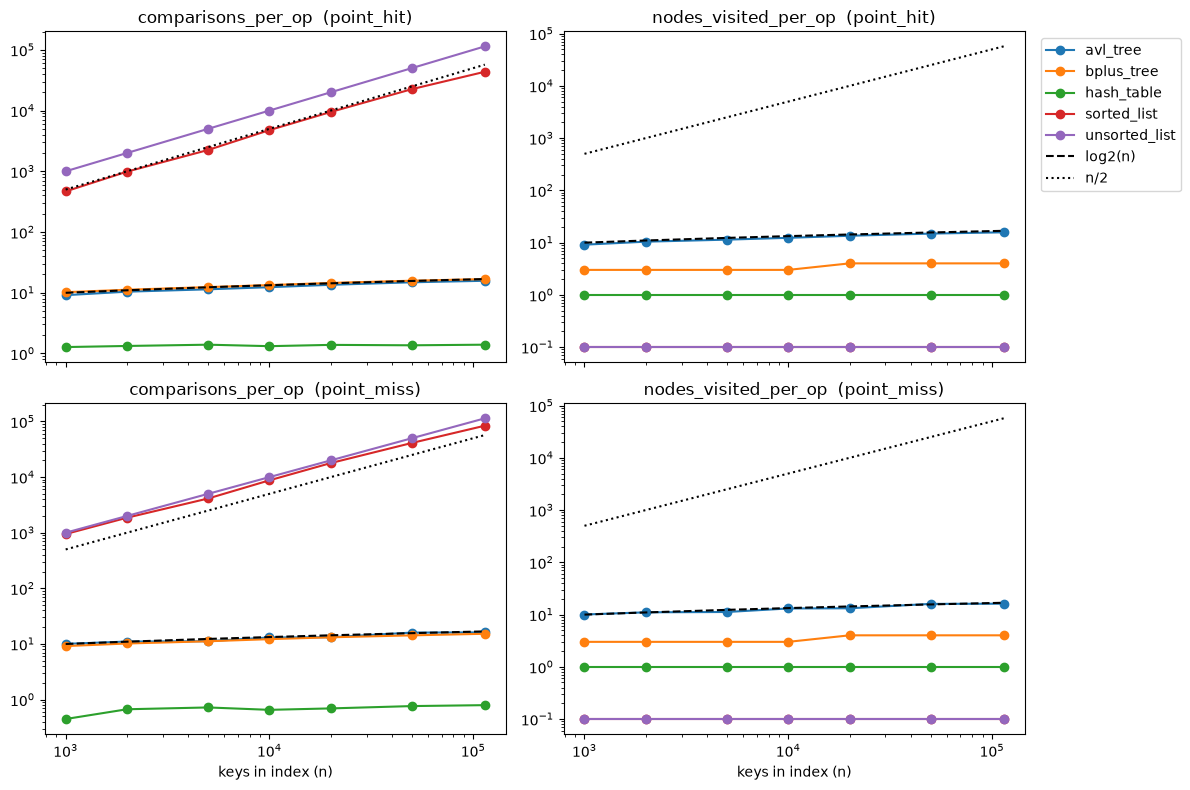

In [6]:
counted = e2[e2["comparisons"].notna()]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
ns = np.array(sorted(counted["n_keys"].unique()))

for col, metric in enumerate(["comparisons_per_op", "nodes_visited_per_op"]):
    for row, op in enumerate(ops):
        ax = axes[row, col]
        for index_type, g in counted[counted["operation"] == op].groupby("index_type"):
            med = g.groupby("n_keys")[metric].median()
            ax.plot(med.index, med.values.clip(min=1e-1), marker="o", label=index_type)
        ax.plot(ns, np.log2(ns), "k--", label="log2(n)")
        ax.plot(ns, ns / 2, "k:", label="n/2")
        ax.set(xscale="log", yscale="log", title=f"{metric}  ({op})")
axes[1, 0].set_xlabel("keys in index (n)"); axes[1, 1].set_xlabel("keys in index (n)")
axes[0, 1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

In [7]:
# resizes during lookups: should be 0, because reset_stats() ran after the build.
counted.groupby(["index_type", "operation"])["resizes"].max().unstack()

operation,point_hit,point_miss
index_type,,
avl_tree,0.0,0.0
bplus_tree,0.0,0.0
hash_table,0.0,0.0
sorted_list,0.0,0.0
unsorted_list,0.0,0.0


## Observations (fill in yourself)

- Hash table vs expected O(1): matches on lookups. Comparisons stay near 1 per lookup (about 1.3 for hits) and nodes visited is exactly 1 at every n. The timing slope of 0.25 to 0.34 is close to ref_dict (0.29 to 0.37), so most of that growth is probably cache effects and not the algorithm. E2 can't show how the table behaves while it grows, because reset_stats() zeroes resizes before the timed lookups. I need to check the E1 build data before calling the hash table healthy overall.
- Unsorted list vs expected O(n): linear, with a comparisons slope of 1.00 (exactly n comparisons per lookup, 114,000 at the largest n). Hits and misses cost the same because search must return every value stored under a key, and track_id has duplicates, so it can't stop at the first match. This is how a no-index baseline should behave, so I don't see a bug here. The timing slope of 1.26 is a bit steeper than the counters, probably from cache effects as the list outgrows the CPU caches.
- Anything in the counters that does not match what the code should do: sorted_list should be O(log n), but its comparisons slope is 0.97 for hits and 0.96 for misses, and its timing slope is about 1.18. Its comparisons are close to linear: about 0.4n for hits and 0.7n for misses at n=114,000. ref_bisect (0.33 hit, 0.18 miss) and avl_tree (0.11 comparisons slope) look right. On misses sorted_list is about twice as slow as the unsorted list at the largest n. Something in sorted_list.search is doing linear work, probably a scan where a binary search should be. This isn't my index, so I'll pass it to whoever owns it.

## Before vs after the fixes

Same machine, same E2 workload and seeds, two code versions: `45879fa` (original) and `fa5c1ad` (all fixes).
The sorted list (INC-02) and the hash table (INC-03) were fixed in between. The hash table fix changed *build* behavior,
so its lookups should look the same.

In [8]:
both = all_e2[all_e2["code_version"].isin([BEFORE, AFTER])].copy()
both["phase"] = both["code_version"].map({BEFORE: "before", AFTER: "after"})
both["us_per_op"] = both["total_ns"] / both["n_ops"] / 1_000
both["comparisons_per_op"] = both["comparisons"] / both["n_ops"]

rows = []
for (phase, op, index_type), g in both.groupby(["phase", "operation", "index_type"]):
    ns = sorted(g["n_keys"].unique())
    med_us = [g[g["n_keys"] == n]["us_per_op"].median() for n in ns]
    med_cmp = [g[g["n_keys"] == n]["comparisons_per_op"].median() for n in ns]
    rows.append({"operation": op, "index_type": index_type, "phase": phase,
                 "time_slope": slope(ns, med_us),
                 "comparisons_slope": slope(ns, np.clip(med_cmp, 1e-9, None)) if not np.isnan(med_cmp[0]) else np.nan})

compare = (pd.DataFrame(rows).round(2)
           .pivot(index=["operation", "index_type"], columns="phase",
                  values=["time_slope", "comparisons_slope"])
           .reindex(columns=["before", "after"], level=1))
compare

time_slope       comparisons_slope      
phase                        before after            before after
operation  index_type                                            
point_hit  avl_tree            0.30  0.24              0.11  0.11
           bplus_tree          0.23  0.17              0.11  0.11
           hash_table          0.34  0.29              0.01  0.02
           ref_bisect          0.33  0.29               NaN   NaN
           ref_dict            0.37  0.40               NaN   NaN
           sorted_list         1.18  0.20              0.97  0.10
           unsorted_list       1.26  1.12              1.00  1.00
point_miss avl_tree            0.17  0.13              0.11  0.11
           bplus_tree          0.12  0.10              0.11  0.11
           hash_table          0.25  0.23              0.09  0.07
           ref_bisect          0.18  0.15               NaN   NaN
           ref_dict            0.29  0.30               NaN   NaN
           sorted_list         1.19  0.14              0.96  0.12
           unsorted_list       1.26  1.11              1.00  1.00

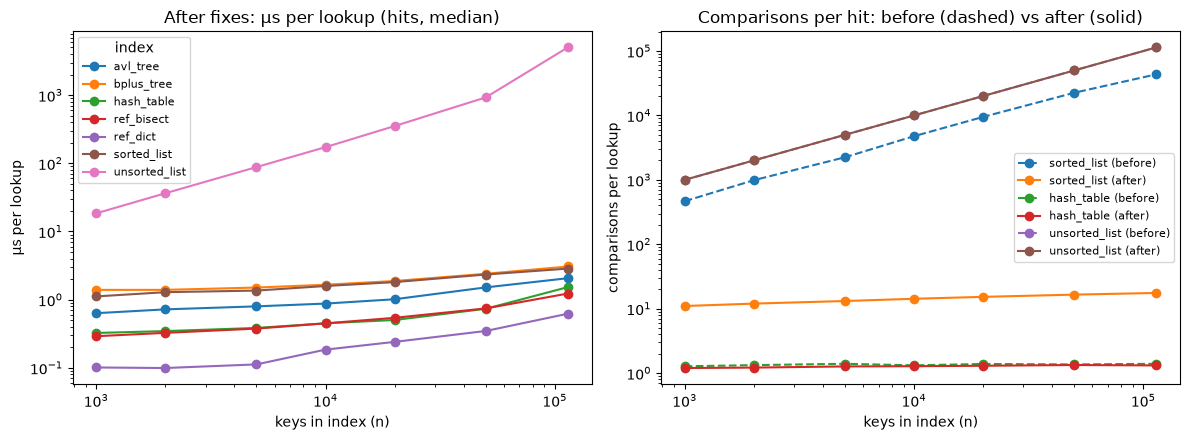

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: lookup cost after the fixes, all indexes (hits). Compare with the "before" figure above.
after_hits = both[(both["phase"] == "after") & (both["operation"] == "point_hit")]
for index_type, g in after_hits.groupby("index_type"):
    med = g.groupby("n_keys")["us_per_op"].median()
    axes[0].plot(med.index, med.values, marker="o", label=index_type)
axes[0].set(xscale="log", yscale="log", title="After fixes: µs per lookup (hits, median)",
            xlabel="keys in index (n)", ylabel="µs per lookup")
axes[0].legend(title="index", fontsize=8)

# Right: comparisons per hit, before (dashed) vs after (solid), for the two fixed indexes plus the unsorted list.
for index_type in ["sorted_list", "hash_table", "unsorted_list"]:
    for phase, style in [("before", "--"), ("after", "-")]:
        g = both[(both["index_type"] == index_type) & (both["phase"] == phase) & (both["operation"] == "point_hit")]
        med = g.groupby("n_keys")["comparisons_per_op"].median()
        axes[1].plot(med.index, med.values, style, marker="o", label=f"{index_type} ({phase})")
axes[1].set(xscale="log", yscale="log", title="Comparisons per hit: before (dashed) vs after (solid)",
            xlabel="keys in index (n)", ylabel="comparisons per lookup")
axes[1].legend(fontsize=8)
plt.tight_layout()

*Add your own before/after bullets here: what changed for the sorted list, why the hash table lookups did not change,
and why the unsorted list's times differ between runs while its comparison counts are identical.*